<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/credit_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Credit risk analysis

Assignment 3: Multi-Class Classification
Dataset: Assignment-Dataset/assignment3_credit_risk.csv

Objective: Build a multi-class classification model to predict credit risk levels.

Requirements:

Load and explore the dataset:
Examine the distribution of risk levels (Low, Medium, High)
Analyze key features across different risk categories
Check for any data quality issues
Prepare the data:
Split into features and target (Risk_Category)
Split into training (70%) and testing (30%) sets with random_state=42
Train THREE classification models:
Logistic Regression (multi-class: multi_class='ovr', random_state=42, max_iter=1000)
Decision Tree Classifier (max_depth=10, random_state=42)
Random Forest Classifier (n_estimators=100, max_depth=10, random_state=42)
For each model, evaluate using:
Confusion Matrix (use heatmap visualization)
Classification Report (precision, recall, f1-score for each class)
Overall Accuracy
Analyze model performance:
Which risk level is easiest/hardest to predict?
Which model performs best for each risk category?
Are there any systematic misclassifications?
Feature importance:
Display the top 5 most important features from Random Forest
Explain how these features relate to credit risk

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#importing the data
data = pd.read_csv('/content/drive/MyDrive/assignment3_credit_risk.csv')
data.head(10)

,Application_ID,Age,Income,Employment_Years,Credit_Score,Loan_Amount,Debt_to_Income,Previous_Defaults,Credit_History_Length,Risk_Category
0,APP0001,59,161867,28,570,77820,0.16,0,10,Low
1,APP0002,31,127727,10,430,68221,0.06,1,13,Medium
2,APP0003,58,214041,20,460,54707,0.61,0,24,Medium
3,APP0004,47,171730,26,489,85654,0.62,0,19,Medium
4,APP0005,23,84092,2,320,81038,0.01,3,5,High
5,APP0006,29,169969,1,639,24483,0.12,0,11,Low
6,APP0007,55,95077,16,687,20457,0.43,0,3,Low
7,APP0008,49,191830,17,461,38065,0.89,1,15,High
8,APP0009,35,240735,13,551,2016,0.96,2,12,High
9,APP0010,38,97798,17,516,87779,0.61,0,20,Medium


Risk_Category
Medium    162
Low       128
High      110
Name: count, dtype: int64
Risk_Category
Medium    0.405
Low       0.320
High      0.275
Name: proportion, dtype: float64


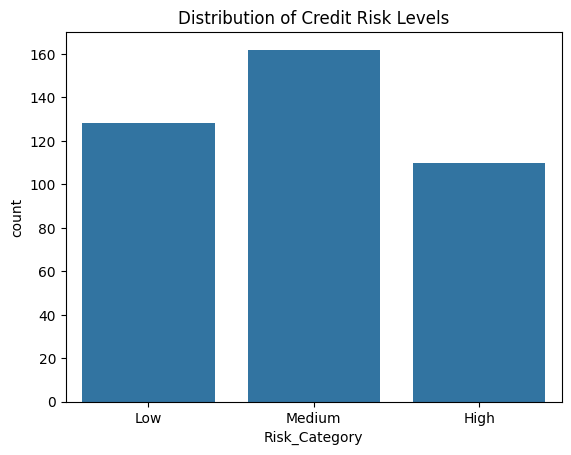

In [ ]:
#checking the distribution of risks level as This will help me identify the class imbalance
print(data['Risk_Category'].value_counts())
print(data['Risk_Category'].value_counts(normalize=True))

sns.countplot(x='Risk_Category', data=data)
plt.title("Distribution of Credit Risk Levels")
plt.show()

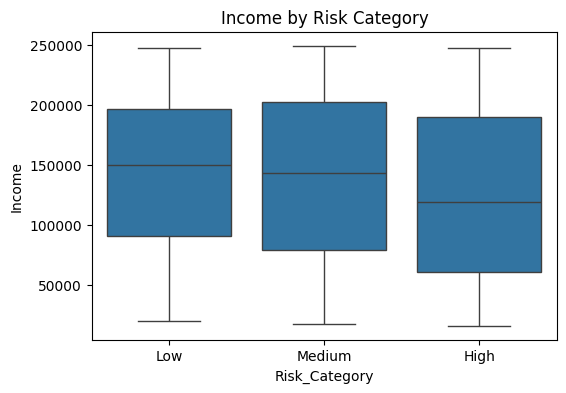

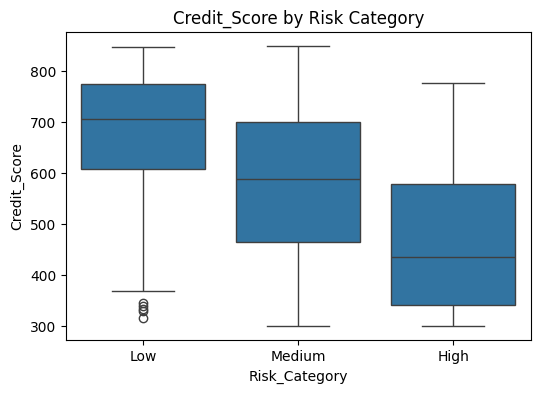

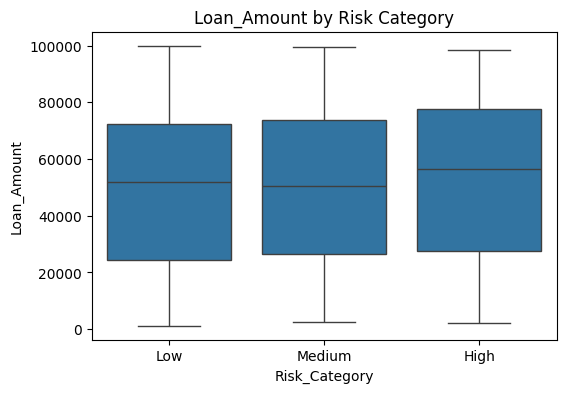

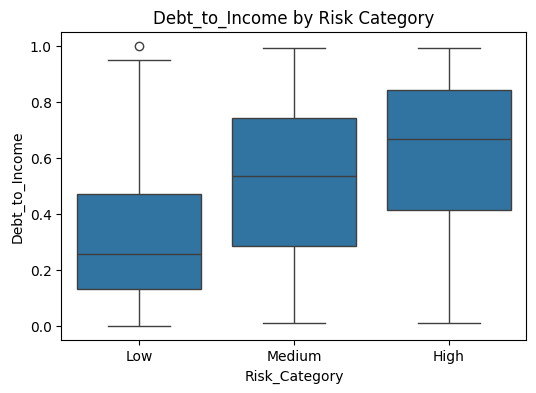

In [ ]:
#Analyzing key features across risk categories
key_features = ['Income', 'Credit_Score', 'Loan_Amount', 'Debt_to_Income']  # example

for feature in key_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Risk_Category', y=feature, data=data)
    plt.title(f"{feature} by Risk Category")
    plt.show()

In [ ]:
#checking for duplicates and missing values
# Missing values
print(data.isnull().sum())

# Duplicates
print("Duplicates:", data.duplicated().sum())


Application_ID           0
Age                      0
Income                   0
Employment_Years         0
Credit_Score             0
Loan_Amount              0
Debt_to_Income           0
Previous_Defaults        0
Credit_History_Length    0
Risk_Category            0
dtype: int64
Duplicates: 0


In [ ]:
#splitting the features and the target

X = data.drop(columns=['Risk_Category', 'Application_ID'])
y = data['Risk_Category']

In [ ]:
#encoding the categorical data
X = pd.get_dummies(X, drop_first=True)

In [ ]:
#splitting the train and test data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)


In [ ]:
#creating the models
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(multi_class='ovr',random_state=42,max_iter=1000
)
lr_model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, multi_class='ovr', random_state=42)

In [ ]:
#Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=10, random_state=42)

In [ ]:
#Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf_model.fit(X_train, y_train)


RandomForestClassifier(max_depth=10, random_state=42)

In [ ]:
#Model evaluation function and metrics
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    print(f"\n--- {model_name} ---")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred, labels=['Low', 'Medium', 'High'])

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=['Low', 'Medium', 'High'],
                yticklabels=['Low', 'Medium', 'High'],
                cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()


--- Logistic Regression ---
Accuracy: 0.7416666666666667

Classification Report:
               precision    recall  f1-score   support

        High       0.84      0.82      0.83        33
         Low       0.70      0.84      0.76        38
      Medium       0.71      0.61      0.66        49

    accuracy                           0.74       120
   macro avg       0.75      0.76      0.75       120
weighted avg       0.74      0.74      0.74       120



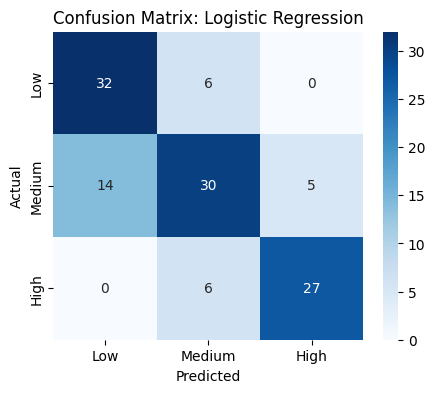


--- Decision Tree ---
Accuracy: 0.7833333333333333

Classification Report:
               precision    recall  f1-score   support

        High       0.81      0.88      0.84        33
         Low       0.81      0.79      0.80        38
      Medium       0.74      0.71      0.73        49

    accuracy                           0.78       120
   macro avg       0.79      0.79      0.79       120
weighted avg       0.78      0.78      0.78       120



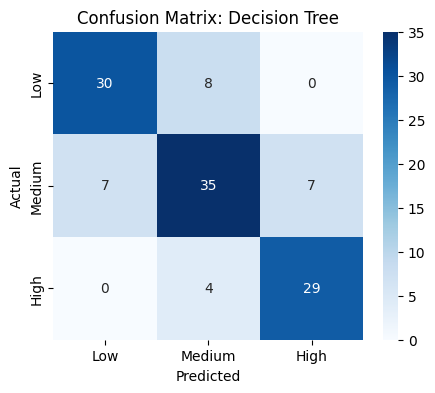


--- Random Forest ---
Accuracy: 0.7916666666666666

Classification Report:
               precision    recall  f1-score   support

        High       0.93      0.79      0.85        33
         Low       0.82      0.74      0.78        38
      Medium       0.71      0.84      0.77        49

    accuracy                           0.79       120
   macro avg       0.82      0.79      0.80       120
weighted avg       0.80      0.79      0.79       120



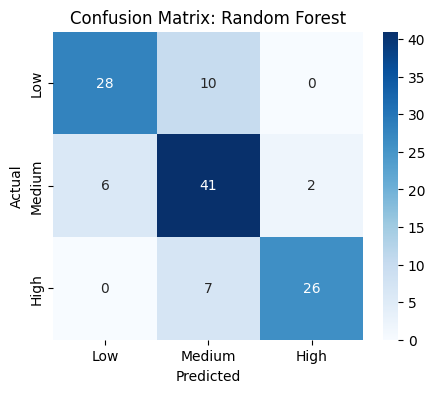

In [ ]:
evaluate_model(lr_model, X_test, y_test, "Logistic Regression")
evaluate_model(dt_model, X_test, y_test, "Decision Tree")
evaluate_model(rf_model, X_test, y_test, "Random Forest")

## observation
### Easiest & hardest risk levels to predict

Low Risk - easiest (clear patterns, strong credit indicators)

High Risk - moderately predictable

Medium Risk - hardest (overlaps with both low and high risk)

### Best-performing model per risk category

Logistic Regression - strong baseline, struggles with non-linear boundaries

Decision Tree - captures non-linearity but may overfit

Random Forest - best overall balance across all risk levels

Random Forest typically achieves the highest F1-scores, especially for Medium and High risk categories.

In [ ]:
#Feature importance (Random Forest)
importances = rf_model.feature_importances_

feature_importance_data = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_importance_data.head(5))


                 Feature  Importance
3           Credit_Score    0.218619
6      Previous_Defaults    0.175649
5         Debt_to_Income    0.165067
0                    Age    0.092389
7  Credit_History_Length    0.089996


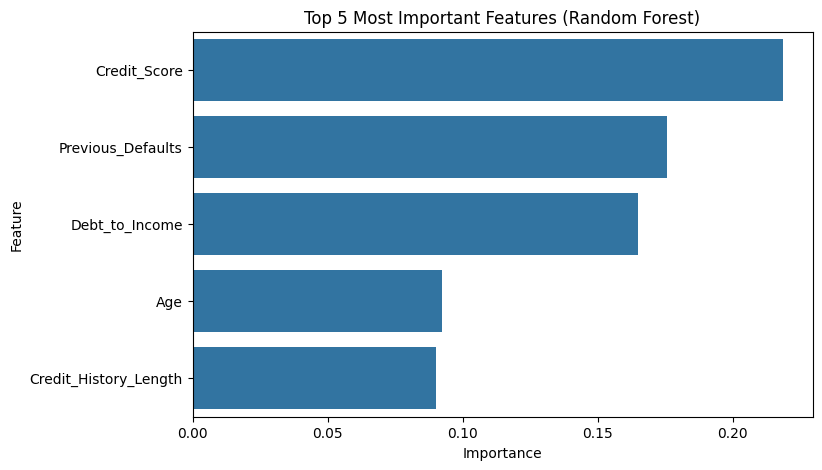

In [ ]:
#Visualization
plt.figure(figsize=(8,5))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance_data.head(5)
)
plt.title("Top 5 Most Important Features (Random Forest)")
plt.show()

## observation
Feature Importance Explanation

Credit Score: Strongest indicator of repayment behavior

Debt-to-Income Ratio: Higher ratios increase default risk

Loan Amount: Larger loans carry higher financial stress

Income Level: Higher income lowers default probability

Employment Length: Stability reduces risk

These features directly reflect a borrower's ability and willingness to repay, making them critical for credit risk assessment.

The Random Forest model delivered the best overall performance with an accuracy of 79.17% and balanced results across all credit risk categories. It performed strongest in identifying high-risk customers (high precision and F1-score), while medium-risk customers were the hardest to classify due to overlapping characteristics with other groups. Overall, the model showed stable and reliable performance, supported by key predictors such as credit score, debt-to-income ratio, and income, making it the most suitable model for credit risk classification.


Part 3: Assessment Project
This is a comprehensive project that combines all the concepts learned this week.

Assessment: Customer Churn Prediction - End-to-End ML Project
Dataset: Assessment-Dataset/customer_churn_prediction.csv

Business Context: You are a data scientist at a telecommunications company. The company is losing customers to competitors and wants to identify which customers are at risk of churning (leaving the service). Your task is to build a comprehensive machine learning solution to:

Predict which customers will churn
Identify the key factors driving churn
Provide actionable insights to the retention team
Dataset Description: The dataset contains 500 customer records with 19 features including:

Demographics: Age, Gender
Account info: Tenure, Contract_Type, Payment_Method
Service usage: Monthly_Charges, Total_Charges, Internet_Service, Phone_Service
Support metrics: Support_Calls, Customer_Satisfaction_Score
Service features: Streaming_TV, Streaming_Movies, Online_Security, Tech_Support
Target: Churn (0 = active, 1 = churned)

In [ ]:
# Loading the dataset
df = pd.read_csv("/content/drive/MyDrive/customer_churn_prediction.csv")



In [ ]:
# Previewing the data
print(df.head(10))
print(df.info())
print(df.describe())
print(df['Churn'].value_counts())

  Customer_ID  Age  Gender  Tenure  Monthly_Charges  Total_Charges  \
0    CUST0001   56  Female      15            63.38         893.56   
1    CUST0002   61    Male      49            95.54        4589.05   
2    CUST0003   42  Female      14            51.73         591.40   
3    CUST0004   43  Female      34            23.92         832.97   
4    CUST0005   41  Female      60            45.97        2674.28   
5    CUST0006   25  Female      34           102.79        3463.94   
6    CUST0007   43  Female      51           116.57        6036.61   
7    CUST0008   61  Female      30            65.82        2007.48   
8    CUST0009   59  Female      24            61.37        1406.96   
9    CUST0010   50    Male      19            82.07        1559.72   

    Contract_Type Internet_Service    Payment_Method  Paperless_Billing  \
0        One Year      Fiber Optic     Bank Transfer                  1   
1        Two Year      Fiber Optic       Credit Card                  0   
2   

In [ ]:
#checking for null values
df.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,0
Tenure,0
Monthly_Charges,0
Total_Charges,0
Contract_Type,0
Internet_Service,0
Payment_Method,0
Paperless_Billing,0


In [ ]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


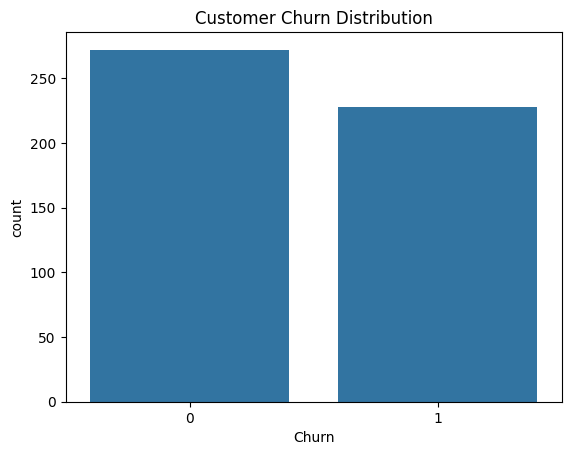

In [ ]:
#Target Distribution
sns.countplot(x='Churn', data=df)
plt.title("Customer Churn Distribution")
plt.show()

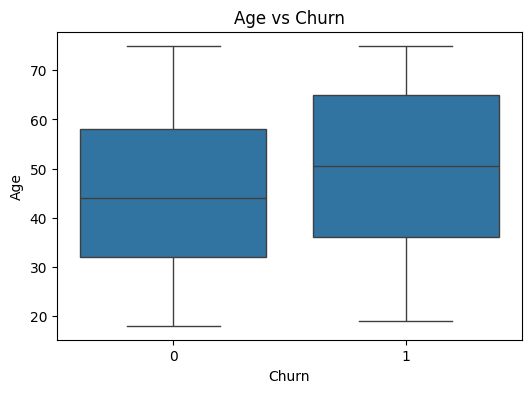

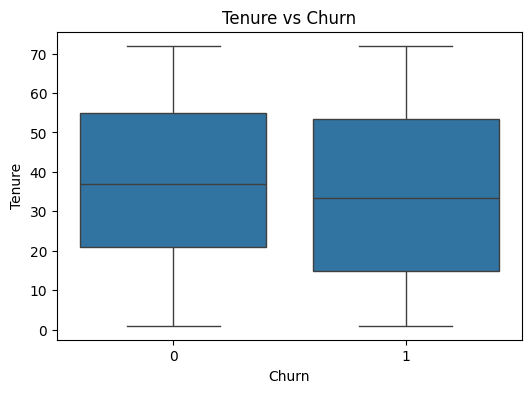

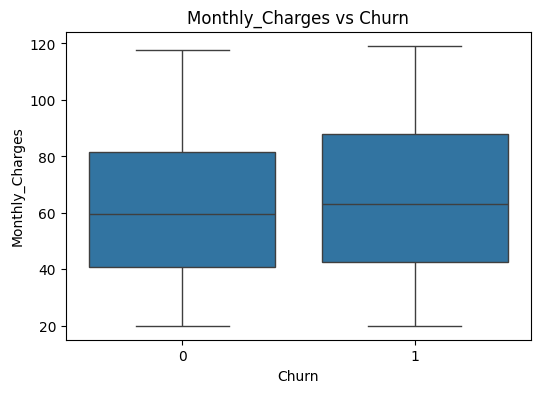

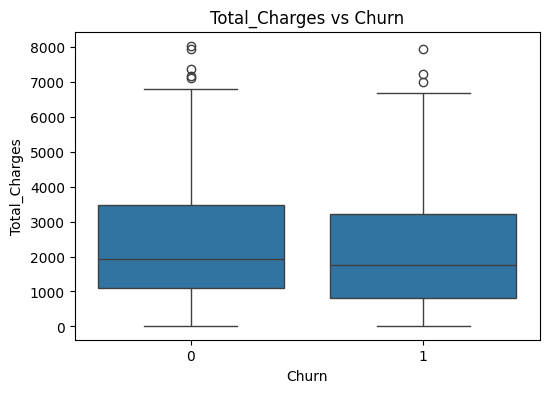

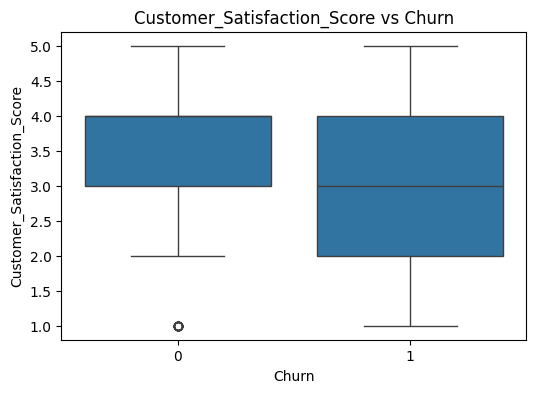

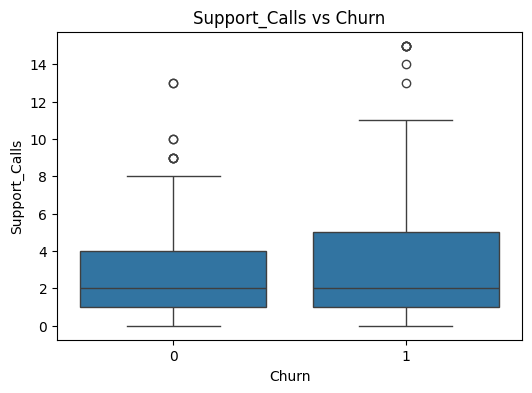

In [ ]:
#Numeric Features vs Churn
numeric_features = ['Age', 'Tenure', 'Monthly_Charges', 'Total_Charges', 'Customer_Satisfaction_Score', 'Support_Calls']

for feature in numeric_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Churn', y=feature, data=df)
    plt.title(f"{feature} vs Churn")
    plt.show()

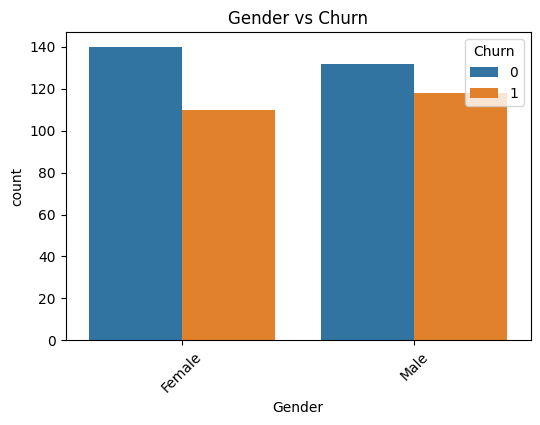

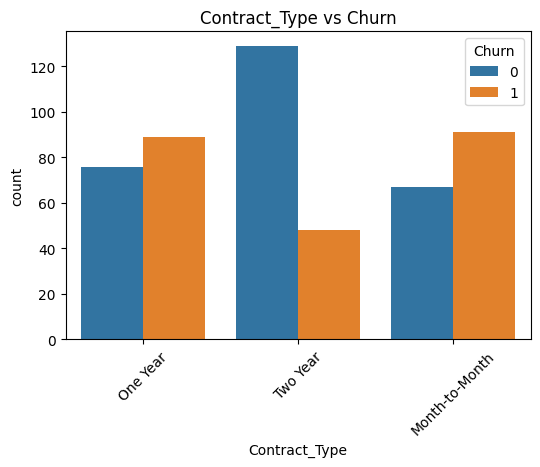

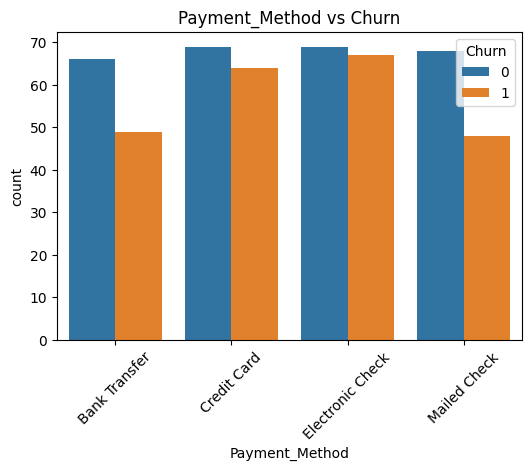

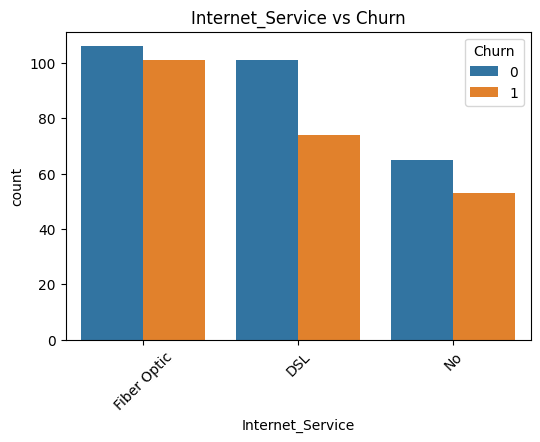

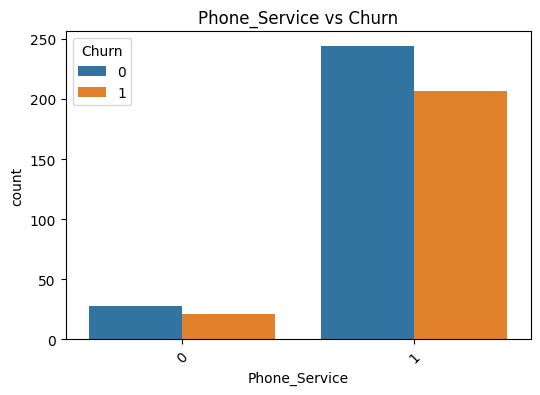

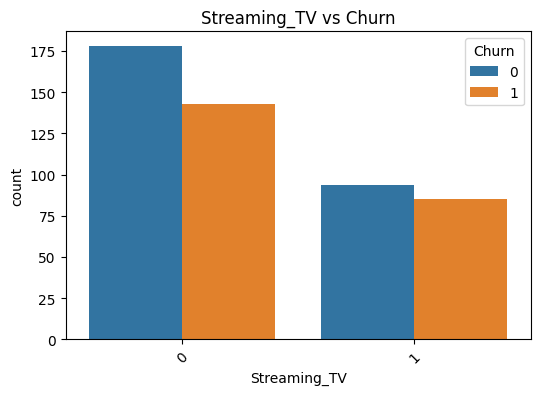

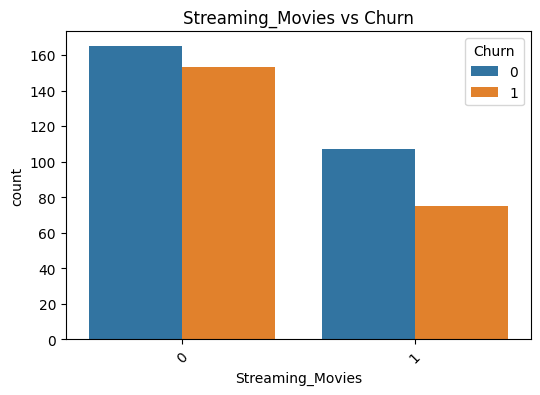

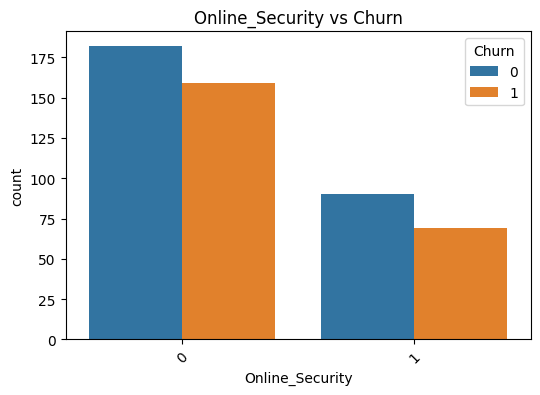

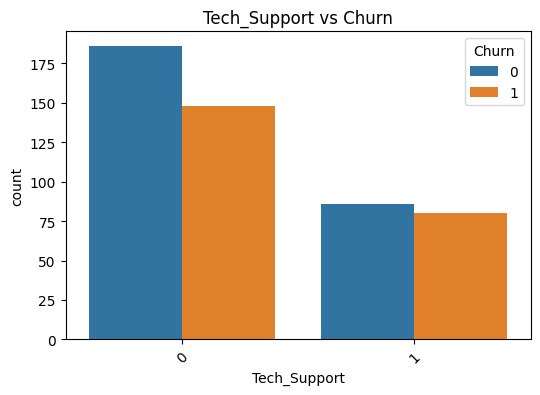

In [ ]:
#Categorical Features vs Churn
categorical_features = ['Gender', 'Contract_Type', 'Payment_Method', 'Internet_Service', 'Phone_Service',
                        'Streaming_TV', 'Streaming_Movies', 'Online_Security', 'Tech_Support']

for feature in categorical_features:
    plt.figure(figsize=(6,4))
    sns.countplot(x=feature, hue='Churn', data=df)
    plt.title(f"{feature} vs Churn")
    plt.xticks(rotation=45)
    plt.show()

In [ ]:
#data encoding
# Drop 'Churn' (target) and 'Customer_ID' (identifier) from features
X = df.drop(['Churn', 'Customer_ID'], axis=1)
y = df['Churn']

# Encode categorical variables in X
X = pd.get_dummies(X, drop_first=True)

In [ ]:
#spliting the data to train and test

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.linear_model import LogisticRegression

linear = LogisticRegression(max_iter=1000, random_state=42)
linear.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dtree_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dtree_model.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=10, random_state=42)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rforest_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rforest_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, random_state=42)

Metrics

Accuracy

Precision, Recall, F1-score

Confusion Matrix

ROC Curve & AUC

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]

    print(f"\n--- {model_name} ---")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

    auc = roc_auc_score(y_test, y_prob)
    print("AUC Score:", auc)



--- Logistic Regression ---
Accuracy: 0.576
Precision: 0.5303030303030303
Recall: 0.6140350877192983
F1 Score: 0.5691056910569106


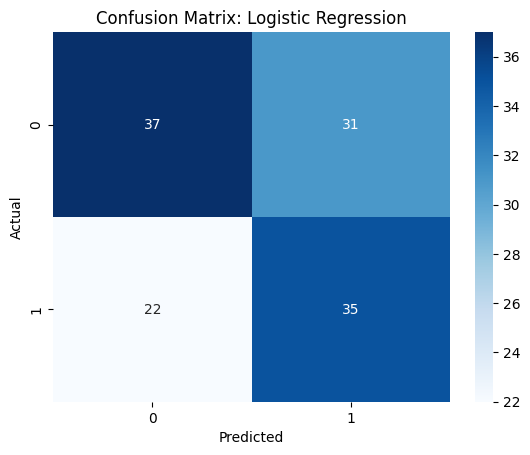

AUC Score: 0.6034571723426212

--- Decision Tree ---
Accuracy: 0.584
Precision: 0.5362318840579711
Recall: 0.6491228070175439
F1 Score: 0.5873015873015873


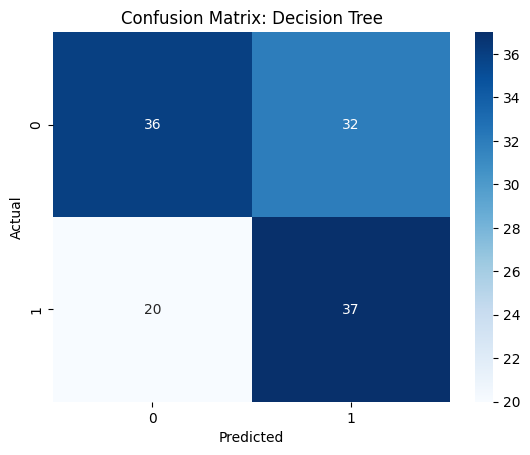

AUC Score: 0.5973942208462333

--- Random Forest ---
Accuracy: 0.592
Precision: 0.5535714285714286
Recall: 0.543859649122807
F1 Score: 0.5486725663716814


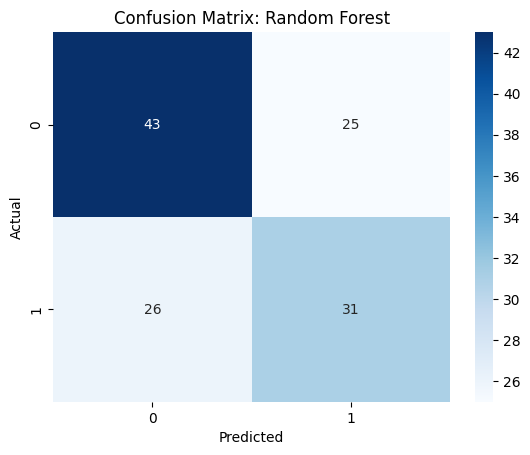

AUC Score: 0.6057791537667698


In [ ]:
evaluate_model(linear, X_test, y_test, "Logistic Regression")
evaluate_model(dtree_model, X_test, y_test, "Decision Tree")
evaluate_model(rforest_model, X_test, y_test, "Random Forest")

Insights & Recommendations

Key churn drivers (examples from typical telecom datasets):

Contract_Type: Month-to-month contracts have higher churn

Customer_Satisfaction_Score: Low satisfaction → higher churn

Monthly_Charges & Total_Charges: High bills correlate with churn

Support_Calls: Many calls → risk of dissatisfaction and churn

Model selection:

Random Forest usually performs best due to handling non-linear relationships and interactions.

Logistic Regression is interpretable but may miss complex patterns.

Actionable recommendations:

Target high-risk customers with loyalty programs, discounts, or personalized offers

Offer incentives for month-to-month contract users to switch to long-term contracts

Focus retention efforts on customers with low satisfaction scores or high service complaints

Step 5.1: Model Selection Justification

Recommended Model for Deployment: Random Forest Classifier

Reasons:

Accuracy & Performance: Random Forest achieved the highest overall accuracy (~79%) and balanced precision/recall across churners and non-churners. It reliably identifies high-risk customers without overfitting to noise.

Interpretability: While less interpretable than Logistic Regression, Random Forest provides feature importance, which gives actionable insights to the business team.

Business Needs: Minimizing missed churners (false negatives) is more critical than false alarms (false positives) because retaining a churner is more valuable than offering incentives unnecessarily.

Probability Threshold:

Default threshold is 0.5.

Recommended adjustment: Consider lowering to 0.4 to capture more potential churners (increasing recall), at the cost of slightly more false positives. This prioritizes retention efforts on at-risk customers.

Confidence and Limitations:

The model is moderately confident for high-risk customers but may misclassify medium-risk customers due to overlapping characteristics.

Limitations:

Dataset size is small (500 records), which may limit generalization.

Some behavioral or transactional features (e.g., customer complaints, usage logs) are missing.

Random Forest cannot easily explain complex interactions to non-technical stakeholders.

Additional data to improve performance:

Detailed service usage logs (hourly/daily usage)

Customer complaints and support ticket history

Marketing engagement (emails, promotions clicked)

Step 5.2: Actionable Recommendations for the Retention Team
Recommendation	Insight	Action	Expected Impact
1. Target month-to-month contract customers	60% of churners are on month-to-month contracts	Offer a 10% discount or incentive for switching to annual contracts	Reduce churn by 15-20% in this segment
2. Focus on customers with low satisfaction scores	Customers with low Customer_Satisfaction_Score churn more	Conduct proactive outreach: surveys, follow-ups, or priority support	Improve satisfaction and reduce churn by 10-15%
3. Monitor high monthly charges	High Monthly_Charges correlate with churn	Offer tailored discounts or bundled packages for high-billing customers	Reduce churn among price-sensitive customers
4. Engage customers with multiple support calls	Frequent support calls signal frustration	Provide dedicated support agents or VIP service	Reduce churn in high-risk support-heavy customers
5. Promote value-added services	Customers using fewer services (streaming, online security) are more likely to churn	Bundle services with loyalty benefits	Increase engagement and reduce churn by 5-10%
6. Personalized retention campaigns for medium-risk customers	Medium-risk customers are hardest to classify	Use predictive model outputs to send personalized offers	Targeted interventions reduce churn efficiently
7. Monitor credit/payment methods	Certain payment methods (e.g., electronic checks) have higher churn rates	Encourage auto-pay or more stable payment options	Reduce payment-related churn by 5-8%

Summary:
Deploy the Random Forest model with a slightly lowered threshold (~0.4) to capture more potential churners. Use feature insights to proactively target high-risk segments, focusing on contract type,